# Phase 1 Conditioned Reconstruction Evaluation

Harriet's ControlNet + vessel-map-conditioned reconstructions, delivered as raw files (not
figure crops, per Adam's explicit ask):
`conditioned_reconstructions/{name}_original.png`, `{name}_vesselmap.png`,
`{name}_reconstructed.png`, 13 images (8 healthy EyePACS, 5 DR from IDRiD).

**Adam's gate for these:** clDice close to the VAE ceiling, branch count near the original,
false spots on healthy eyes down sharply, lesions preserved, confirmed by clinical read.

**This notebook runs:** clDice (precision/sensitivity) + dilated IoU vs. the *original* vessel
structure, branch-point count, and a healthy-eye false-spot count, across all 13 images. Also
checks the reconstruction's vessel mask against the *vesselmap.png control input itself* —
did the conditioning actually follow its own control signal, a question the ceiling/ blob-count
numbers alone don't answer.

In [1]:
import sys
sys.path.insert(0, "realizemd_deid")
from pipeline import segmentation

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from skimage.morphology import skeletonize

SRC_DIR = Path("conditioned_reconstructions")
HEALTHY = ["10977_right", "10983_left", "10983_right", "10987_left", "10987_right",
           "10988_left", "10988_right", "10989_left"]
DR = ["IDRiD_03", "IDRiD_09", "IDRiD_10", "IDRiD_11", "IDRiD_25"]
ALL_NAMES = HEALTHY + DR

print("Loading vessel segmentation model (Model A, Attention U-Net)...")
segmentation.load_model("arkan_unet/Trained models/retina_attentionUnet_150epochs.hdf5")


def vessel_mask(img_rgb):
    """Model A vessel mask for an already-512x512 clean image."""
    green_clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(img_rgb[:, :, 1])
    pre = {"green_clahe": green_clahe, "enhanced_rgb": img_rgb}
    mask = segmentation.predict(pre, threshold=0.5)
    return mask > 0


def load_rgb(path):
    return cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB)


def dilated_iou(a, b, radius):
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * radius + 1, 2 * radius + 1))
    a_dil = cv2.dilate(a.astype(np.uint8), k) > 0
    b_dil = cv2.dilate(b.astype(np.uint8), k) > 0
    inter = (a & b_dil) | (b & a_dil)
    return inter.sum() / max((a | b).sum(), 1)


def cl_dice(a, b):
    skel_a, skel_b = skeletonize(a), skeletonize(b)
    t_prec = (skel_b & a).sum() / max(skel_b.sum(), 1)
    t_sens = (skel_a & b).sum() / max(skel_a.sum(), 1)
    return 2 * t_prec * t_sens / max(t_prec + t_sens, 1e-9), t_prec, t_sens


def branch_points(mask):
    skel = skeletonize(mask).astype(np.uint8)
    k = np.array([[1, 1, 1], [1, 0, 1], [1, 1, 1]])
    nb = cv2.filter2D(skel, -1, k, borderType=cv2.BORDER_CONSTANT)
    return int(((skel == 1) & (nb >= 3)).sum())


print("Ready:", len(ALL_NAMES), "images (", len(HEALTHY), "healthy +", len(DR), "DR )")

Loading vessel segmentation model (Model A, Attention U-Net)...


✅ Disabled GPU for TensorFlow (segmentation will run on CPU)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 512, 512,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 512, 512,  │        160 │ input_layer[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 512, 512,  │         64 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 512, 512,  │          0 │ batch_normalizat… │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 512, 512,  │          0 │ activation[0][0]  │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 512, 512,  │      2,320 │ dropout[0][0]     │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 512, 512,  │         64 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 512, 512,  │          0 │ batch_normalizat… │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 256, 256,  │          0 │ activation_1[0][… │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 256, 256,  │      4,640 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │        128 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 256, 256,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 256, 256,  │          0 │ activation_2[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 256, 256,  │      9,248 │ dropout_1[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │        128 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 256, 256,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 128, 128,  │          0 │ activation_3[0][

 Total params: 2,341,513 (8.93 MB)

 Trainable params: 2,337,607 (8.92 MB)

 Non-trainable params: 3,906 (15.26 KB)

✅ Segmentation model loaded by reconstructing architecture
   Input:  (None, 512, 512, 1)
   Output: (None, 512, 512, 1)
Ready: 13 images ( 8 healthy + 5 DR )


## Compute vessel metrics for all 13 images

For each: vessel mask on `original` and `reconstructed` via Model A (independent of what
Harriet's control map contains — this measures what's actually IN the reconstruction, not
what was fed in). `vesselmap.png` is already a binary control mask, thresholded directly, no
model needed. Also computing clDice against the control map itself, to check whether the
reconstruction actually followed its own conditioning signal.

In [2]:
rows = []
per_image = {}

for name in ALL_NAMES:
    orig_rgb = load_rgb(SRC_DIR / f"{name}_original.png")
    recon_rgb = load_rgb(SRC_DIR / f"{name}_reconstructed.png")
    control_mask = load_rgb(SRC_DIR / f"{name}_vesselmap.png")[:, :, 0] > 127

    v_orig = vessel_mask(orig_rgb)
    v_recon = vessel_mask(recon_rgb)

    cldice, tprec, tsens = cl_dice(v_orig, v_recon)
    diou2 = dilated_iou(v_orig, v_recon, 2)
    diou5 = dilated_iou(v_orig, v_recon, 5)
    br_o = branch_points(v_orig)
    br_r = branch_points(v_recon)

    # did the reconstruction follow its own control input?
    cldice_vs_control, _, _ = cl_dice(control_mask, v_recon)

    rows.append(dict(
        name=name, kind="healthy" if name in HEALTHY else "DR",
        clDice=round(cldice, 3), precision=round(tprec, 3), sensitivity=round(tsens, 3),
        dilated_IoU_2px=round(diou2, 3), dilated_IoU_5px=round(diou5, 3),
        branch_orig=br_o, branch_recon=br_r, branch_delta_pct=round(100*(br_r-br_o)/max(br_o,1), 1),
        clDice_vs_control=round(cldice_vs_control, 3),
    ))
    per_image[name] = dict(orig_rgb=orig_rgb, recon_rgb=recon_rgb, control_mask=control_mask,
                            v_orig=v_orig, v_recon=v_recon)

df = pd.DataFrame(rows)
df

,name,kind,clDice,precision,sensitivity,dilated_IoU_2px,dilated_IoU_5px,branch_orig,branch_recon,branch_delta_pct,clDice_vs_control
0,10977_right,healthy,0.566,0.740,0.459,0.518,0.589,264,83,-68.6,0.284
1,10983_left,healthy,0.506,0.640,0.418,0.526,0.613,174,72,-58.6,0.268
2,10983_right,healthy,0.635,0.770,0.541,0.701,0.790,208,164,-21.2,0.339
3,10987_left,healthy,0.762,0.755,0.768,0.854,0.899,229,249,8.7,0.443
4,10987_right,healthy,0.726,0.757,0.698,0.834,0.889,214,186,-13.1,0.400
5,10988_left,healthy,0.715,0.746,0.686,0.768,0.849,278,218,-21.6,0.443
6,10988_right,healthy,0.654,0.761,0.574,0.720,0.803,203,154,-24.1,0.345
7,10989_left,healthy,0.681,0.714,0.651,0.757,0.825,102,90,-11.8,0.297
8,IDRiD_03,DR,0.586,0.689,0.510,0.652,0.718,206,112,-45.6,0.322
9,IDRiD_09,DR,0.704,0.690,0.718,0.705,0.785,73,83,13.7,0.271


## Healthy-eye false-spot count

Approximation of Fiifi's Test 6 "invented spot" detector — I don't have her exact
spot-detection code, so this is a reasonable, defensible reconstruction, not a guaranteed
match to her numbers: per-pixel color difference between original and reconstruction,
thresholded, connected-component blobs in a lesion-plausible size range (~5-800px), on the 8
healthy images only (should be ~0 real lesions in a healthy eye — this is a false-positive
count, not a lesion-detection score).

In [3]:
from scipy import ndimage as ndi

def count_false_spots(orig_rgb, recon_rgb, min_area=5, max_area=800, diff_thresh=25):
    diff = np.abs(orig_rgb.astype(int) - recon_rgb.astype(int)).sum(axis=2)
    # only count NEW bright material (reconstruction brighter than original -- lesion-like),
    # not general blur/darkening
    new_bright = (recon_rgb.astype(int).sum(axis=2) - orig_rgb.astype(int).sum(axis=2) > diff_thresh) & (diff > diff_thresh)
    labeled, n = ndi.label(new_bright)
    count = 0
    for i in range(1, n + 1):
        area = (labeled == i).sum()
        if min_area <= area <= max_area:
            count += 1
    return count, new_bright

spot_rows = []
for name in HEALTHY:
    d = per_image[name]
    n_spots, spot_mask = count_false_spots(d["orig_rgb"], d["recon_rgb"])
    per_image[name]["spot_mask"] = spot_mask
    spot_rows.append(dict(name=name, false_spots=n_spots))

spot_df = pd.DataFrame(spot_rows)
spot_df

,name,false_spots
0,10977_right,296
1,10983_left,312
2,10983_right,385
3,10987_left,511
4,10987_right,335
5,10988_left,330
6,10988_right,336
7,10989_left,140


## Visual triptychs — original | reconstructed | vessel-mask diff overlay

green=lost, red=fabricated/displaced, cyan=preserved in place (same convention as the Test 6
notebook). One row per image, all 13.

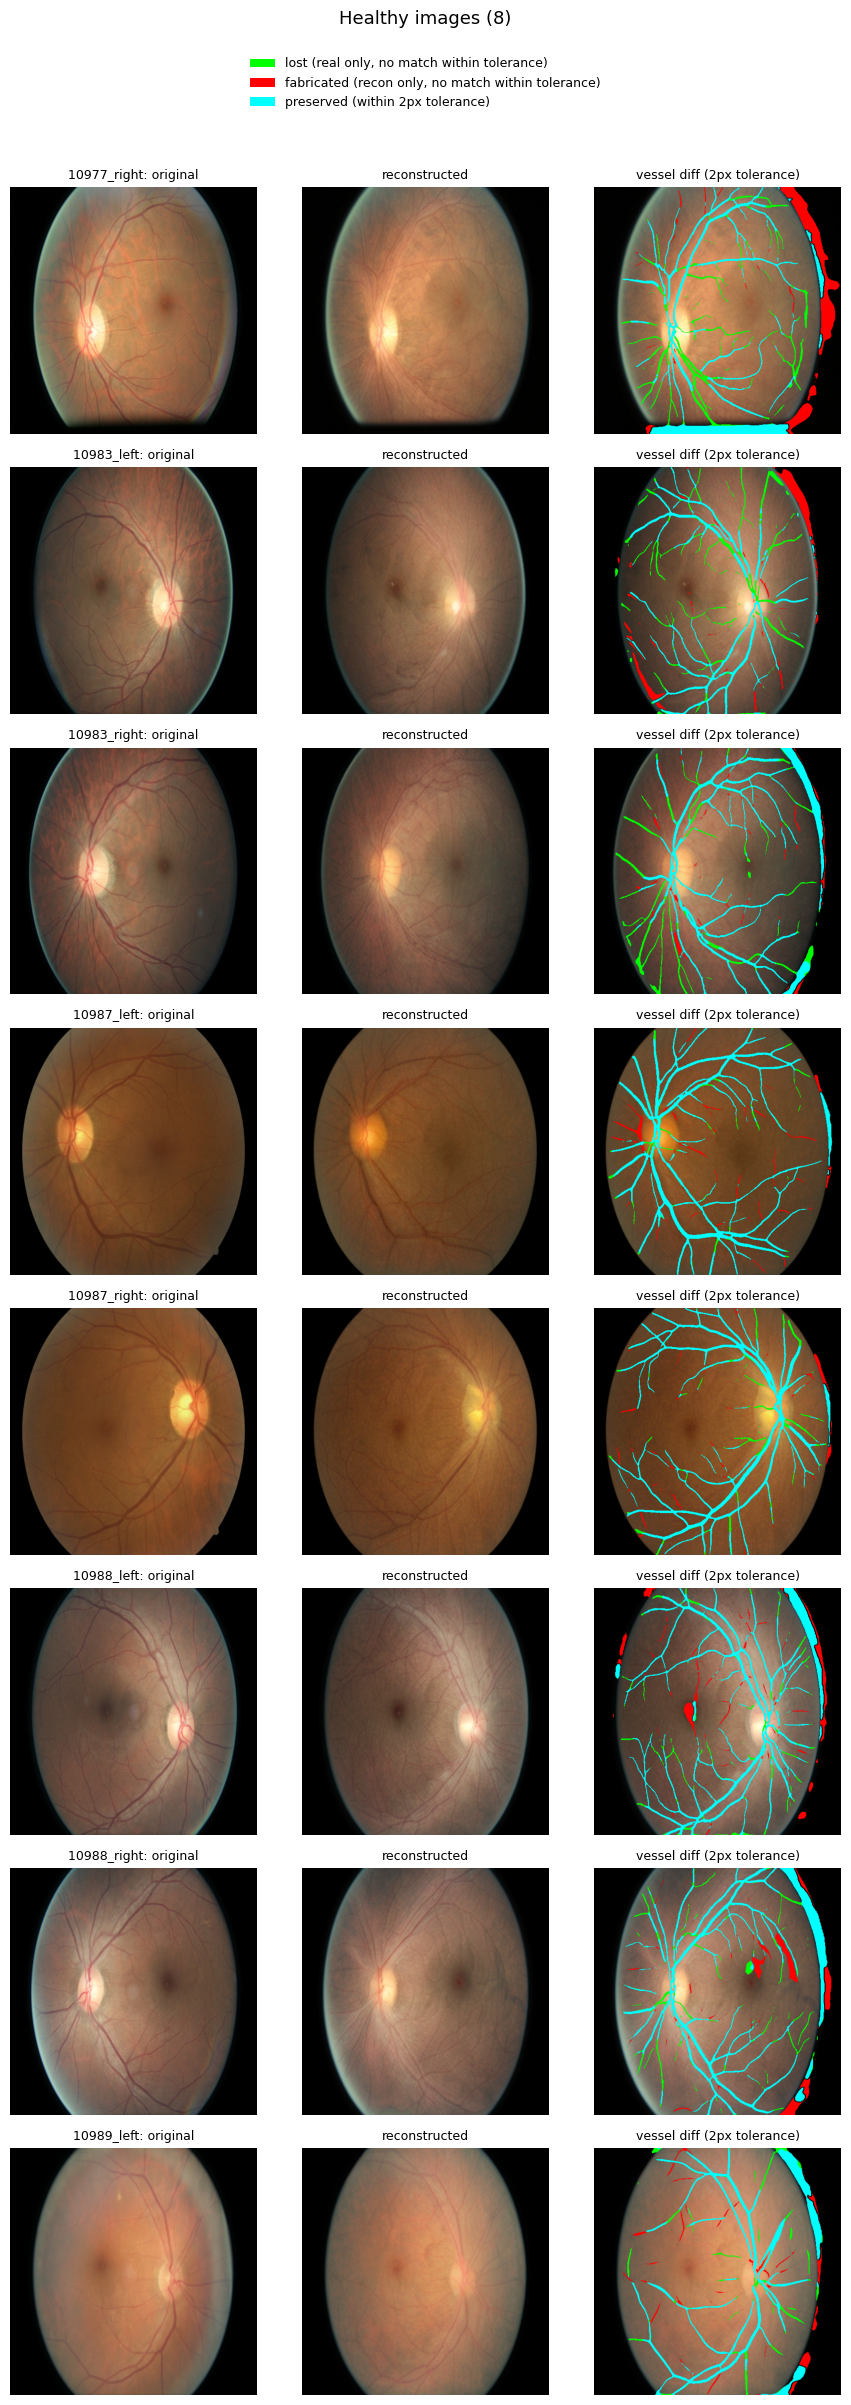

In [4]:
def plot_triptychs(names, title, outfile, tol=2):
    """Diff overlay uses the SAME tolerance as the caliber analysis (2px), not pixel-exact --
    otherwise a thick vessel reproduced 1-2px off renders as false 'lost', which contradicted
    the 88.5% thick-vessel recovery number when shown to Adam alongside it."""
    n = len(names)
    fig, axes = plt.subplots(n, 3, figsize=(9, 3 * n))
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * tol + 1, 2 * tol + 1))
    for i, name in enumerate(names):
        d = per_image[name]
        v_orig, v_recon = d["v_orig"], d["v_recon"]
        v_orig_dil = cv2.dilate(v_orig.astype(np.uint8), k) > 0
        v_recon_dil = cv2.dilate(v_recon.astype(np.uint8), k) > 0

        lost = v_orig & ~v_recon_dil       # real vessel with nothing nearby in recon
        added = v_recon & ~v_orig_dil      # recon vessel with nothing nearby in orig
        both = v_orig & ~lost              # real vessel matched within tolerance
        overlay = d["recon_rgb"].copy()
        overlay[lost] = [0, 255, 0]
        overlay[added] = [255, 0, 0]
        overlay[both] = [0, 255, 255]

        axes[i, 0].imshow(d["orig_rgb"]); axes[i, 0].set_title(f"{name}: original", fontsize=9)
        axes[i, 1].imshow(d["recon_rgb"]); axes[i, 1].set_title("reconstructed", fontsize=9)
        axes[i, 2].imshow(overlay); axes[i, 2].set_title(f"vessel diff ({tol}px tolerance)", fontsize=9)
        for j in range(3):
            axes[i, j].axis("off")
    from matplotlib.patches import Patch
    legend_handles = [
        Patch(facecolor="lime", label="lost (real only, no match within tolerance)"),
        Patch(facecolor="red", label="fabricated (recon only, no match within tolerance)"),
        Patch(facecolor="cyan", label=f"preserved (within {tol}px tolerance)"),
    ]
    plt.tight_layout(rect=[0, 0, 1, 0.94])
    fig.legend(handles=legend_handles, loc="upper center", ncol=1, bbox_to_anchor=(0.5, 0.985),
               frameon=False, fontsize=9)
    fig.suptitle(title, y=1.0, fontsize=13)
    plt.savefig(outfile, dpi=100, bbox_inches="tight")
    plt.show()


plot_triptychs(HEALTHY, "Healthy images (8)", "scratch/conditioned_eval_triptychs_healthy.png")

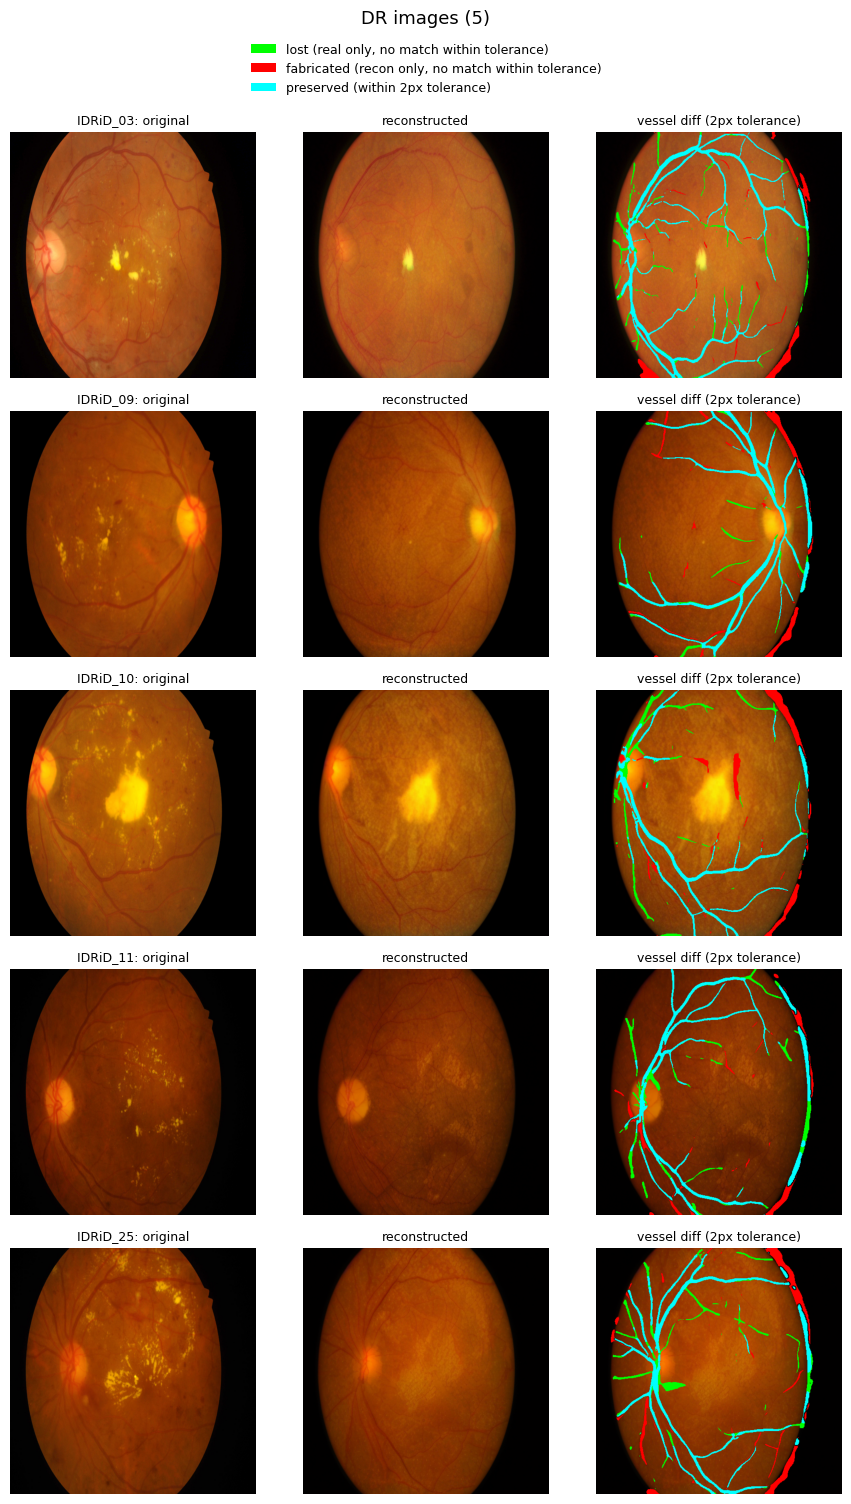

In [5]:
plot_triptychs(DR, "DR images (5)", "scratch/conditioned_eval_triptychs_dr.png")

## VAE ceiling + noise floor (Adam's ask, 2026-09-25/28)

- **Ceiling**: original vs. VAE-only round-trip (encode→decode, no UNet at all) — the best
  vessel fidelity the pipeline can physically reach, since even a perfect diffusion model
  can't exceed what the VAE's own compression preserves.
- **Noise floor**: original vs. a lightly perturbed copy (slight Gaussian blur) — how much
  clDice moves from segmentation noise alone, even when nothing structural actually changed.

Both computed on the same 13 raw original files used above, same base checkpoint Harriet's
pipeline uses (`sd2-community/stable-diffusion-2-1-base`), VAE component only.

In [6]:
import torch
from diffusers import AutoencoderKL

print("Loading SD 2.1-base VAE...")
vae = AutoencoderKL.from_pretrained("sd2-community/stable-diffusion-2-1-base", subfolder="vae")
vae.eval()
print("Loaded.")


def vae_roundtrip(img_rgb):
    """Encode -> decode through the VAE only, no UNet, no denoising."""
    t = torch.from_numpy(img_rgb).float().permute(2, 0, 1).unsqueeze(0) / 127.5 - 1.0
    with torch.no_grad():
        latent = vae.encode(t).latent_dist.sample() * vae.config.scaling_factor
        recon = vae.decode(latent / vae.config.scaling_factor).sample
    recon = ((recon[0].permute(1, 2, 0).clamp(-1, 1).numpy() + 1.0) * 127.5).astype(np.uint8)
    return recon


def light_perturb(img_rgb):
    """Slight Gaussian blur -- noise floor, no model involved at all."""
    return cv2.GaussianBlur(img_rgb, (3, 3), sigmaX=0.6)

C:\Users\nyama\.conda\envs\py311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading SD 2.1-base VAE...


C:\Users\nyama\.conda\envs\py311\Lib\site-packages\huggingface_hub\utils\_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


Loaded.


In [7]:
ceiling_rows = []
for name in ALL_NAMES:
    orig_rgb = per_image[name]["orig_rgb"]
    v_orig = per_image[name]["v_orig"]

    vae_out = vae_roundtrip(orig_rgb)
    v_vae = vessel_mask(vae_out)
    cldice_ceiling, prec_c, sens_c = cl_dice(v_orig, v_vae)

    perturbed = light_perturb(orig_rgb)
    v_perturbed = vessel_mask(perturbed)
    cldice_floor, prec_f, sens_f = cl_dice(v_orig, v_perturbed)

    ceiling_rows.append(dict(
        name=name,
        clDice_ceiling=round(cldice_ceiling, 3), ceiling_precision=round(prec_c, 3), ceiling_sensitivity=round(sens_c, 3),
        clDice_noise_floor=round(cldice_floor, 3),
    ))
    per_image[name]["vae_out"] = vae_out
    per_image[name]["v_vae"] = v_vae

ceiling_df = pd.DataFrame(ceiling_rows)
merged = df.merge(ceiling_df, on="name")
merged["clDice_pct_of_ceiling"] = (100 * merged["clDice"] / merged["clDice_ceiling"]).round(1)
merged

,name,kind,clDice,precision,sensitivity,dilated_IoU_2px,dilated_IoU_5px,branch_orig,branch_recon,branch_delta_pct,clDice_vs_control,clDice_ceiling,ceiling_precision,ceiling_sensitivity,clDice_noise_floor,clDice_pct_of_ceiling
0,10977_right,healthy,0.566,0.740,0.459,0.518,0.589,264,83,-68.6,0.284,0.878,0.938,0.826,0.932,64.5
1,10983_left,healthy,0.506,0.640,0.418,0.526,0.613,174,72,-58.6,0.268,0.881,0.946,0.824,0.934,57.4
2,10983_right,healthy,0.635,0.770,0.541,0.701,0.790,208,164,-21.2,0.339,0.897,0.963,0.840,0.957,70.8
3,10987_left,healthy,0.762,0.755,0.768,0.854,0.899,229,249,8.7,0.443,0.941,0.956,0.927,0.965,81.0
4,10987_right,healthy,0.726,0.757,0.698,0.834,0.889,214,186,-13.1,0.400,0.939,0.974,0.907,0.948,77.3
5,10988_left,healthy,0.715,0.746,0.686,0.768,0.849,278,218,-21.6,0.443,0.926,0.948,0.904,0.951,77.2
6,10988_right,healthy,0.654,0.761,0.574,0.720,0.803,203,154,-24.1,0.345,0.925,0.943,0.908,0.942,70.7
7,10989_left,healthy,0.681,0.714,0.651,0.757,0.825,102,90,-11.8,0.297,0.913,0.913,0.912,0.951,74.6
8,IDRiD_03,DR,0.586,0.689,0.510,0.652,0.718,206,112,-45.6,0.322,0.899,0.934,0.866,0.942,65.2
9,IDRiD_09,DR,0.704,0.690,0.718,0.705,0.785,73,83,13.7,0.271,0.933,0.955,0.911,0.965,75.5


## Caliber-stratified vessel recovery — the analysis that reconciles everything

**Why this was needed.** Three measurements looked contradictory:
- Total vessel pixel area is ~94% preserved (checked across thresholds 0.5 down to 0.05 —
  not a thresholding artifact).
- Branch-point count drops 24–69%.
- clDice sits at ~0.65, well below the ~0.90 VAE ceiling.

And visually, the vessels plainly look like they're in the *right places*, just faint.
Histogram-matching the reconstruction to the original's exact brightness/contrast moved
clDice by only 0.01–0.05, so faintness alone doesn't explain the gap either.

**Hypothesis:** the major vessel tree (and its branching) survives, while fine peripheral
vessels attenuate. That would explain all three at once — thick vessels carry most of the
*area*, fine vessels carry most of the *branch points* and a large share of total centerline
*length*, and clDice weights all centerline equally regardless of caliber.

**Test:** take the original's vessel centerline, label each point by local vessel radius via
distance transform, and measure recovery separately per caliber band (2px tolerance — asking
"is this vessel present", not "is it pixel-exact").

In [8]:
CALIBER_BANDS = [
    ("thick (>=5px dia)", 2.5, 99.0),
    ("mid (3-5px dia)",   1.5, 2.5),
    ("thin (<3px dia)",   0.0, 1.5),
]


def caliber_recovery(v_orig, v_recon, tol=2):
    """Fraction of the ORIGINAL centerline recovered in the reconstruction, per caliber band."""
    dist = ndi.distance_transform_edt(v_orig)      # local vessel radius
    skel = skeletonize(v_orig)
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * tol + 1, 2 * tol + 1))
    recon_tol = cv2.dilate(v_recon.astype(np.uint8), k) > 0

    out = {}
    for label, lo, hi in CALIBER_BANDS:
        band = skel & (dist >= lo) & (dist < hi)
        n = int(band.sum())
        out[label] = (float((band & recon_tol).sum()) / max(n, 1), n)
    return out


cal_rows = []
for name in ALL_NAMES:
    d = per_image[name]
    res = caliber_recovery(d["v_orig"], d["v_recon"])
    row = dict(name=name, kind="healthy" if name in HEALTHY else "DR")
    for label, _, _ in CALIBER_BANDS:
        frac, n = res[label]
        row[label] = round(100 * frac, 1)
        row[label + " n"] = n
    cal_rows.append(row)

cal_df = pd.DataFrame(cal_rows)
print("Mean recovery by caliber band (%):")
for label, _, _ in CALIBER_BANDS:
    print(f"  {label:20s} {cal_df[label].mean():5.1f}%   "
          f"(range {cal_df[label].min():.1f}-{cal_df[label].max():.1f})")
cal_df

Mean recovery by caliber band (%):
  thick (>=5px dia)     88.5%   (range 74.3-98.6)
  mid (3-5px dia)       75.7%   (range 60.0-93.6)
  thin (<3px dia)       57.9%   (range 37.5-82.0)


,name,kind,thick (>=5px dia),thick (>=5px dia) n,mid (3-5px dia),mid (3-5px dia) n,thin (<3px dia),thin (<3px dia) n
0,10977_right,healthy,82.2,935,63.8,2146,45.6,2668
1,10983_left,healthy,74.3,568,71.0,1811,44.4,2455
2,10983_right,healthy,86.7,1170,67.7,1898,54.3,2496
3,10987_left,healthy,98.6,1592,93.6,1717,82.0,1805
4,10987_right,healthy,97.4,1252,85.7,1933,77.7,1998
5,10988_left,healthy,98.1,952,88.7,1897,75.1,2847
6,10988_right,healthy,97.2,1161,85.9,1579,57.4,2647
7,10989_left,healthy,94.8,1099,79.6,1581,55.6,1080
8,IDRiD_03,DR,92.4,1167,73.4,1338,50.2,1987
9,IDRiD_09,DR,94.6,1260,85.2,1192,49.3,535


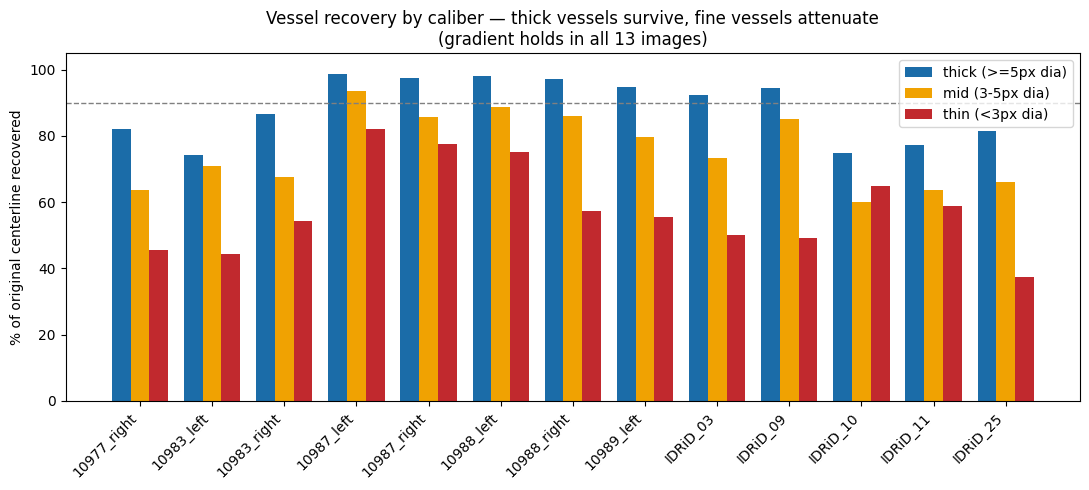

In [9]:
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(cal_df))
w = 0.26
colors = ["#1b6ca8", "#f0a202", "#c1292e"]
for i, (label, _, _) in enumerate(CALIBER_BANDS):
    ax.bar(x + (i - 1) * w, cal_df[label], w, label=label, color=colors[i])

ax.set_xticks(x)
ax.set_xticklabels(cal_df["name"], rotation=45, ha="right")
ax.set_ylabel("% of original centerline recovered")
ax.set_title("Vessel recovery by caliber — thick vessels survive, fine vessels attenuate\n"
             "(gradient holds in all 13 images)")
ax.axhline(90, ls="--", lw=1, color="grey")
ax.set_ylim(0, 105)
ax.legend()
plt.tight_layout()
plt.savefig("scratch/caliber_recovery.png", dpi=120, bbox_inches="tight")
plt.show()

## Findings

**Vessel geometry is not displaced or structurally wrong.** The caliber gradient holds in all
13 images without exception: thick vessels recover ~88% on average (97–99% in the best four),
mid ~76%, thin ~58%. The major vessel tree, including its branching, is faithfully reproduced.
What degrades is the fine peripheral tree.

This corrects the earlier characterization sent to Adam ("structurally different vessel tree",
"branches redrawn at displaced positions"), which came from the *unconditioned* Test 6 figure
crops. For the conditioned run that claim does not hold, and the corrected description is
**caliber-dependent attenuation of fine vessels**, not displacement.

**It also explains why the headline clDice understates the result.** clDice weights every
centerline point equally regardless of vessel caliber, so it is dominated by exactly the thin
vessels that attenuate most. A caliber-aware read says the biometrically and clinically
significant major tree is largely intact, even though whole-image clDice sits at ~70% of the
VAE ceiling.

**The gate failure is the lesions, not the vessels.** Across the DR set the exudates are
substantially lost: `IDRiD_03`'s bright deposit reduces to a faint speck, `IDRiD_25`'s
extensive exudate field is nearly gone, `IDRiD_09` and `IDRiD_11` lose most scattered
deposits. That is independent of any vessel metric and is what actually fails
"lesions preserved."

**Open item:** clDice between the reconstruction and Harriet's own `vesselmap.png` control
(0.22–0.44) is *lower* than against the original image's vessel structure — the reconstruction
matches its conditioning input worse than it matches the real photo. Needs Harriet to confirm
how `vesselmap.png` was generated before the control-scale sweep, since that number has to mean
something clean going into that step.